# PANALDO | Molecular mechanism diagram generator v1
Editable, reusable schematic diagrams based on reported DFT endpoint distances. Atom indices are zero-based ORCA indices. Positions are schematic, not Cartesian coordinates. Endpoint switching is not a reaction trajectory. The tetrahedral structure has converged but full imaginary-mode confirmation and IRC connectivity remain pending.

Run all cells. Edit `STATES`, `POS`, and `THEME` to draw other systems. Exports: 600 dpi PNG, vector SVG/PDF and standalone interactive HTML.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import plotly.graph_objects as go
from IPython.display import display, HTML
OUT=Path('mechanism_figures'); OUT.mkdir(exist_ok=True)
STATES={
 'Reactant': {'CO':3.1256,'carbonyl':1.284,'CN':1.321,'OH':0.9879,'HO':1.7746},
 'Tetrahedral structure': {'CO':1.4845,'carbonyl':1.3828,'CN':1.4345,'OH':1.5295,'HO':1.0285}}
POS={'C1':(1.3,2.3),'O2':(1.3,4.1),'C0':(0.35,0.65),'N3':(2.35,0.65),'O30':(3.65,2.3),'H32':(5.85,2.3),'O21':(8.15,2.3)}
COL={'C1':'#374151','C0':'#374151','N3':'#2563eb','O2':'#dc2626','O30':'#dc2626','O21':'#dc2626','H32':'#e5e7eb'}
THEMES={'dark':dict(bg='#202020',fg='#f3f4f6',bond='#a3a3a3',blue='#6495ff',green='#41cf9b'), 'white':dict(bg='white',fg='#171717',bond='#777777',blue='#1d4ed8',green='#08734b')}
R={a:(.34 if a=='H32' else .43) for a in POS}
def bonds(state):
    d=STATES[state]; t=state!='Reactant'
    return [('C1','O2','carbonyl','bond',False,(1.95,3.35)),('C1','C0',None,'bond',False,None),('C1','N3','CN','bond',False,(2.15,1.65)),('C1','O30','CO','blue',not t,(2.48,2.95)),('O30','H32','OH','bond',t,(4.75,1.72)),('H32','O21','HO','green',not t,(7.0,2.95))]
def subtitle(state):
    return 'C–O bond formed; proton redistributed' if state!='Reactant' else 'Water-assisted reactant complex'


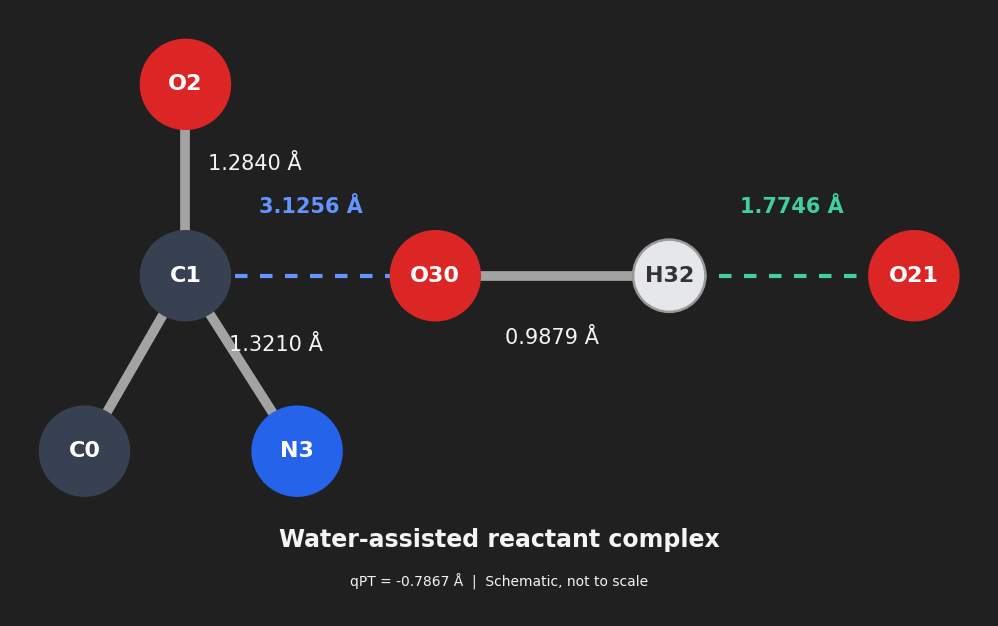

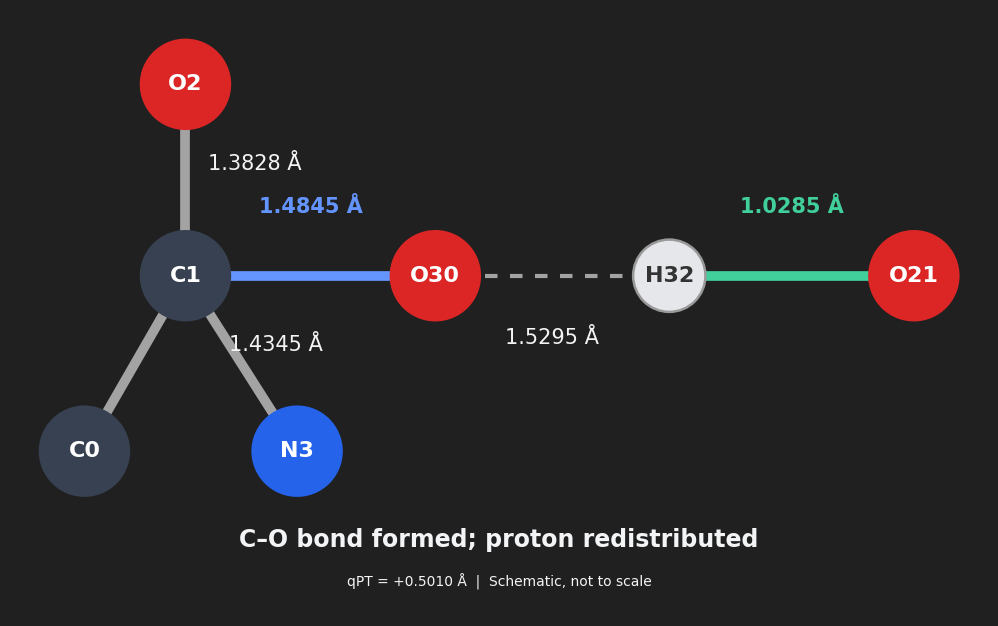

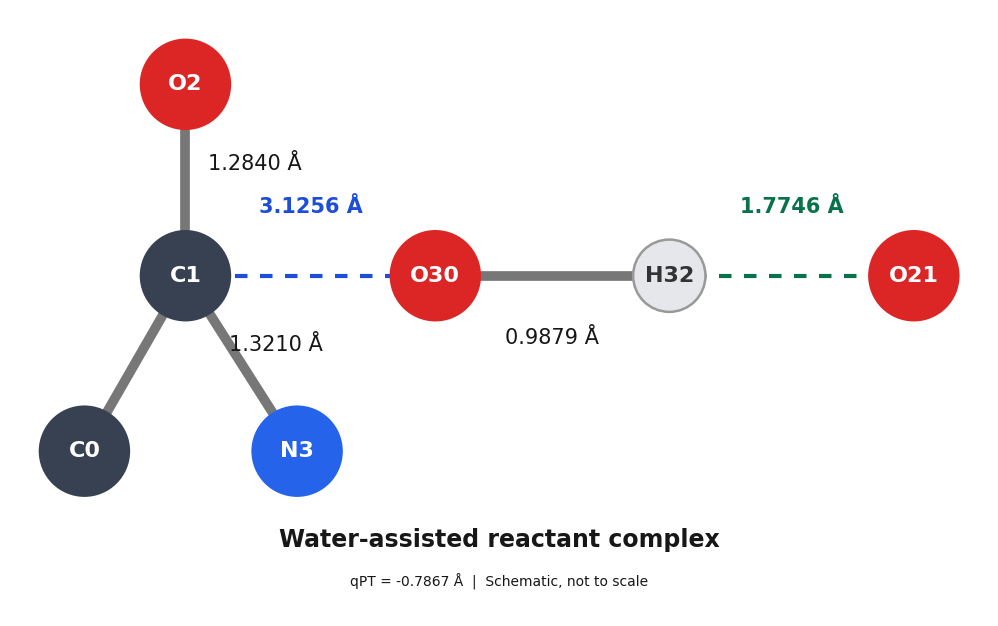

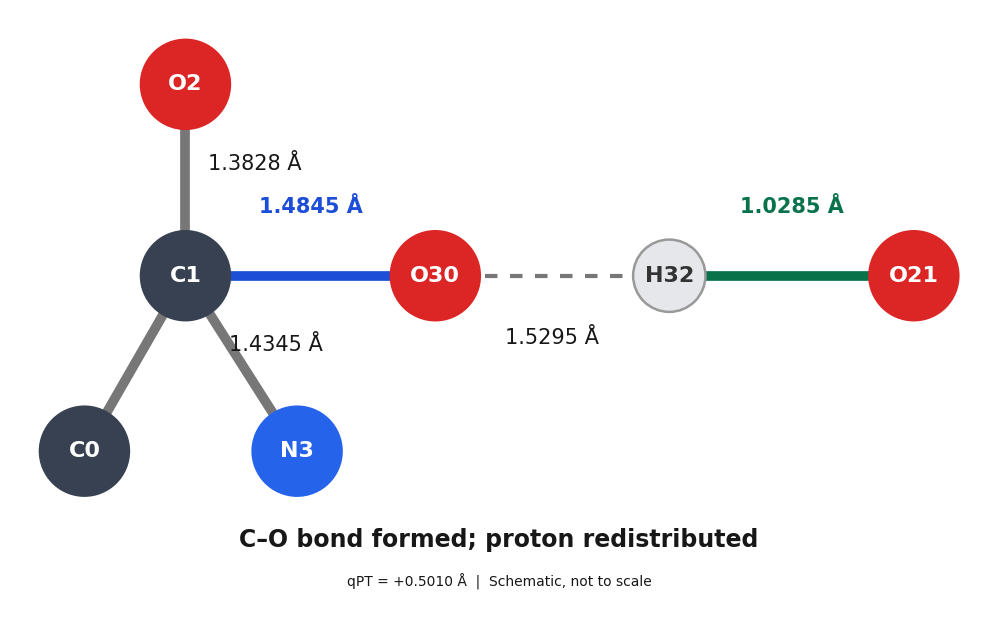

In [2]:
def draw(state='Tetrahedral structure',theme='dark',figsize=(10.5,6.2),dpi=600,export=True):
    c=THEMES[theme]; d=STATES[state]
    fig,ax=plt.subplots(figsize=figsize,facecolor=c['bg']); ax.set_facecolor(c['bg'])
    for a,b,k,col,dashed,labelpos in bonds(state):
        x,y=POS[a]; u,v=POS[b]
        ax.plot([x,u],[y,v],color=c[col],lw=3 if dashed else 7,ls=(0,(3,3)) if dashed else '-',solid_capstyle='round',zorder=1)
        if k:
            ax.text(*labelpos,f'{d[k]:.4f} Å',ha='center',va='center',fontsize=15,fontweight='bold' if col!='bond' else 'normal',color=c[col] if col!='bond' else c['fg'])
    for a,(x,y) in POS.items():
        ax.add_patch(Circle((x,y),R[a],fc=COL[a],ec='#999999' if a=='H32' else 'none',lw=1.8,zorder=3))
        ax.text(x,y,a,ha='center',va='center',fontsize=16,fontweight='bold',color='#333333' if a=='H32' else 'white',zorder=4)
    ax.text(4.25,-.25,subtitle(state),ha='center',fontsize=17,fontweight='bold',color=c['fg'])
    ax.text(4.25,-.62,f"qPT = {d['OH']-d['HO']:+.4f} Å  |  Schematic, not to scale",ha='center',fontsize=10,color=c['fg'])
    ax.set(xlim=(-.35,8.85),ylim=(-.9,4.8),aspect='equal'); ax.axis('off'); fig.tight_layout(pad=.5)
    if export:
        name=state.lower().replace(' ','_')+'_'+theme
        for ext in ('png','svg','pdf'): fig.savefig(OUT/f'{name}.{ext}',dpi=dpi,facecolor=c['bg'],bbox_inches='tight',pad_inches=.12)
    return fig
for theme in THEMES:
    for state in STATES:
        fig=draw(state,theme); display(fig); plt.close(fig)


In [3]:
def interactive(theme='dark'):
    c=THEMES[theme]; fig=go.Figure(); groups=[]
    for state,d in STATES.items():
        start=len(fig.data)
        for a,b,k,col,dashed,lp in bonds(state):
            x,y=POS[a]; u,v=POS[b]
            fig.add_trace(go.Scatter(x=[x,u],y=[y,v],mode='lines',line=dict(color=c[col],width=4 if dashed else 8,dash='dash' if dashed else 'solid'),hoverinfo='skip',showlegend=False))
            if k:
                fig.add_trace(go.Scatter(x=[lp[0]],y=[lp[1]],mode='text',text=[f'{d[k]:.4f} Å'],textfont=dict(size=17,color=c[col] if col!='bond' else c['fg']),hoverinfo='skip',showlegend=False))
        for a,(x,y) in POS.items():
            fig.add_trace(go.Scatter(x=[x],y=[y],mode='markers+text',marker=dict(size=63 if a!='H32' else 50,color=COL[a]),text=[a],textposition='middle center',textfont=dict(size=17,color='#333' if a=='H32' else 'white'),hovertemplate=f'ORCA atom {a}<extra></extra>',showlegend=False))
        fig.add_trace(go.Scatter(x=[4.25],y=[-.32],mode='text',text=[subtitle(state)],textfont=dict(size=20,color=c['fg']),hoverinfo='skip',showlegend=False))
        groups.append(list(range(start,len(fig.data))))
    for j,tr in enumerate(fig.data): tr.visible=j in groups[1]
    buttons=[dict(label=s,method='update',args=[{'visible':[j in g for j in range(len(fig.data))]},{'title':f'{s} | qPT = {STATES[s]["OH"]-STATES[s]["HO"]:+.4f} Å'}]) for s,g in zip(STATES,groups)]
    fig.update_layout(title='Tetrahedral structure | qPT = +0.5010 Å',paper_bgcolor=c['bg'],plot_bgcolor=c['bg'],font=dict(color=c['fg']),height=550,margin=dict(l=15,r=15,t=110,b=25),updatemenus=[dict(type='buttons',direction='right',buttons=buttons,active=1,x=.5,xanchor='center',y=1.16,bgcolor='#555555' if theme=='dark' else '#eeeeee')],xaxis=dict(visible=False,range=[-.4,8.9]),yaxis=dict(visible=False,range=[-.9,4.8],scaleanchor='x',scaleratio=1))
    return fig
for theme in THEMES:
    f=interactive(theme); f.write_html(OUT/f'interactive_{theme}.html',include_plotlyjs=True); f.show(renderer='notebook_connected')


## Interpretation and limits
A decrease in C1–O30 and change in sign of qPT support bond formation and proton redistribution in the reported endpoints. A local minimum requires full frequency validation; a connected reaction pathway requires TS and IRC. The schematic omits spectator atoms and waters; line styles denote selected connectivity, not quantified bond orders. Static exports use custom Matplotlib formatting, not a direct Figentra dependency.